
# BMMC T3 trajectory visualization notebook

This notebook redraws panel **C** in a simplified way for the ATLAS BMMC results under:

```text
/data5/zhangye/ATLAS/results/table2/BMMC
```

For each pairing ratio (`pair_000`, `pair_020`, ..., `pair_100`), it makes a **two-panel figure**:

1. **Predicted Trajectory**: UMAP scatter colored by predicted time (0 to 1).
2. **Reference Trajectory**: the same UMAP layout colored by the **stage category** derived from the provided `stage_map`.

This notebook intentionally keeps the plotting simple:
- no extra arrows,
- no cluttered annotations,
- focus only on whether the predicted time is consistent with the annotated stage order.


In [1]:

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D

try:
    from umap import UMAP
    HAS_UMAP = True
except Exception as e:
    print(f"[Warning] umap-learn is unavailable: {e}")
    HAS_UMAP = False
    from sklearn.decomposition import PCA


In [2]:

# =========================
# User configuration
# =========================
ROOT = Path('/data5/zhangye/ATLAS/results/table2/BMMC')
PAIR_DIRS = ['pair_000', 'pair_020', 'pair_040', 'pair_060', 'pair_080', 'pair_100']
OUT_DIR = ROOT / 'trajectory_visualizations_simple'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Stage map provided by you.
STAGE_MAP = {
    'HSC': 0,
    'Lymph prog': 1,
    'G/M prog': 1,
    'MK/E prog': 1,
    'ID2-hi myeloid prog': 1,
    'CD4+ T naive': 2,
    'CD8+ T naive': 2,
    'Naive CD20+ B': 2,
    'Transitional B': 2,
    'B1 B': 2,
    'Proerythroblast': 2,
    'NK': 3,
    'CD8+ T': 3,
    'CD4+ T activated': 3,
    'CD14+ Mono': 3,
    'CD16+ Mono': 3,
    'pDC': 3,
    'cDC2': 3,
    'ILC': 3,
    'Plasma cell': 3,
    'Erythroblast': 3,
    'Normoblast': 4,
}

# Time colormap: blue -> pink, matching your reference style.
TIME_CMAP = LinearSegmentedColormap.from_list(
    'time_blue_pink', ['#6FA8DC', '#F08AC0']
)

# Stage colormap: 5 ordered categories from light to deep.
STAGE_COLORS = ['#D8E8F7', '#B8D0F0', '#D7C1E8', '#EAA0D0', '#D25D9C']
STAGE_CMAP = ListedColormap(STAGE_COLORS)
STAGE_NORM = BoundaryNorm(np.arange(-0.5, 5.5, 1), STAGE_CMAP.N)


In [3]:

# =========================
# Helper functions
# =========================

def load_npz_dict(path: Path):
    with np.load(path, allow_pickle=False) as data:
        return {k: data[k] for k in data.files}


def load_json(path: Path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)


def first_existing_key(d, candidates):
    for k in candidates:
        if k in d:
            return k
    return None


def get_embedding_matrix(pred):
    # Prefer fused latent representation for UMAP.
    emb_key = first_existing_key(pred, ['h_fused', 'h', 'z', 'latent', 'embedding'])
    if emb_key is not None:
        return pred[emb_key], emb_key

    # Fallback to modality-specific embeddings.
    emb_key = first_existing_key(pred, ['z_atac', 'h_atac', 'atac_latent', 'embed_atac'])
    if emb_key is not None:
        return pred[emb_key], emb_key

    # Last resort: use true RNA, but this is not preferred.
    emb_key = first_existing_key(pred, ['true_rna', 'pred_rna'])
    if emb_key is not None:
        warnings.warn(f'Using {emb_key} as UMAP input because no latent embedding was found.')
        return pred[emb_key], emb_key

    raise KeyError('Could not find a usable embedding matrix in predictions.npz')


def get_time_array(pred):
    key = first_existing_key(pred, ['time', 'time_head', 'pseudotime', 'latent_time'])
    if key is None:
        raise KeyError('Could not find predicted time in predictions.npz')
    t = np.asarray(pred[key]).reshape(-1)
    return t, key


def get_labels_from_npz(pred):
    key = first_existing_key(pred, ['labels', 'label', 'cell_type', 'cell_types'])
    if key is None:
        return None, None
    labels = pred[key].astype(str)
    return labels, key


def get_labels_from_csv(run_dir: Path):
    csv_path = run_dir / 'T3_stage_reference.csv'
    if not csv_path.exists():
        return None, None
    df = pd.read_csv(csv_path)
    # Try common column names.
    for col in ['label', 'labels', 'cell_type', 'stage_label', 'reference_label']:
        if col in df.columns:
            return df[col].astype(str).to_numpy(), col
    # If exactly one object column exists, use it.
    obj_cols = [c for c in df.columns if df[c].dtype == object]
    if len(obj_cols) == 1:
        return df[obj_cols[0]].astype(str).to_numpy(), obj_cols[0]
    return None, None


def labels_to_stage_ids(labels, stage_map):
    stage_ids = np.array([stage_map.get(str(x), np.nan) for x in labels], dtype=float)
    return stage_ids


def compute_layout(X, random_state=1234):
    X = np.asarray(X)
    if X.ndim != 2:
        raise ValueError(f'Expected 2D matrix, got shape={X.shape}')
    if X.shape[1] == 2:
        return X
    if HAS_UMAP:
        reducer = UMAP(n_components=2, n_neighbors=20, min_dist=0.35, metric='euclidean', random_state=random_state)
        return reducer.fit_transform(X)
    else:
        print('[Info] Falling back to PCA(2) because UMAP is unavailable.')
        return PCA(n_components=2, random_state=random_state).fit_transform(X)


def inspect_pair(run_dir: Path):
    print(f'\n===== Inspecting {run_dir.name} =====')
    pred_path = run_dir / 'predictions.npz'
    metrics_path = run_dir / 'metrics.json'
    t3_csv_path = run_dir / 'T3_stage_reference.csv'

    print('predictions.npz:', pred_path.exists())
    print('metrics.json    :', metrics_path.exists())
    print('T3_stage_reference.csv:', t3_csv_path.exists())

    if pred_path.exists():
        pred = load_npz_dict(pred_path)
        for k, v in pred.items():
            print(f'  {k:<18} shape={getattr(v, "shape", None)} dtype={getattr(v, "dtype", None)}')


In [4]:

# Inspect all ratio directories first
for d in PAIR_DIRS:
    inspect_pair(ROOT / d)



===== Inspecting pair_000 =====
predictions.npz: True
metrics.json    : True
T3_stage_reference.csv: True
  cell_ids           shape=(5161,) dtype=<U25
  z_atac             shape=(5161, 32) dtype=float32
  z_rna              shape=(5161, 32) dtype=float32
  h_fused            shape=(5161, 32) dtype=float32
  pred_rna           shape=(5161, 12093) dtype=float32
  true_rna           shape=(5161, 12093) dtype=float32
  t1_true_pca        shape=(5161, 30) dtype=float64
  t1_pred_pca        shape=(5161, 30) dtype=float64
  time               shape=(5161,) dtype=float32
  labels             shape=(5161,) dtype=<U19

===== Inspecting pair_020 =====
predictions.npz: True
metrics.json    : True
T3_stage_reference.csv: True
  cell_ids           shape=(6191,) dtype=<U25
  z_atac             shape=(6191, 32) dtype=float32
  z_rna              shape=(6191, 32) dtype=float32
  h_fused            shape=(6191, 32) dtype=float32
  pred_rna           shape=(6191, 12093) dtype=float32
  true_rna        

In [5]:

# =========================
# Core plotting function
# =========================

def plot_simple_t3_panel(run_dir: Path, save=True, show=True):
    pred_path = run_dir / 'predictions.npz'
    metrics_path = run_dir / 'metrics.json'

    pred = load_npz_dict(pred_path)
    metrics = load_json(metrics_path) if metrics_path.exists() else {}

    X, emb_key = get_embedding_matrix(pred)
    time, time_key = get_time_array(pred)

    labels, label_key = get_labels_from_npz(pred)
    if labels is None:
        labels, label_key = get_labels_from_csv(run_dir)

    if labels is None:
        raise ValueError(
            f'No labels found in {run_dir}. Please check predictions.npz or T3_stage_reference.csv'
        )

    stage_ids = labels_to_stage_ids(labels, STAGE_MAP)
    valid = np.isfinite(stage_ids)

    if len(time) != X.shape[0]:
        raise ValueError(f'Time length {len(time)} does not match embedding rows {X.shape[0]}')
    if len(labels) != X.shape[0]:
        raise ValueError(f'Label length {len(labels)} does not match embedding rows {X.shape[0]}')

    layout = compute_layout(X, random_state=1234)

    fig, axes = plt.subplots(2, 1, figsize=(5.2, 8.6))
    ax1, ax2 = axes

    # -------------------------
    # Top: predicted time
    # -------------------------
    sc1 = ax1.scatter(
        layout[:, 0], layout[:, 1],
        c=time, cmap=TIME_CMAP,
        s=6, alpha=0.85, linewidths=0
    )
    cb1 = plt.colorbar(sc1, ax=ax1, fraction=0.046, pad=0.04)
    cb1.set_label('Predicted time', fontsize=10)
    cb1.set_ticks([0.0, 1.0])

    ax1.set_title('Predicted Trajectory', fontsize=18, pad=10)
    ax1.set_xlabel('UMAP 1', fontsize=11)
    ax1.set_ylabel('UMAP 2', fontsize=11)
    ax1.spines[['top', 'right']].set_visible(False)
    ax1.set_xticks([])
    ax1.set_yticks([])

    # -------------------------
    # Bottom: reference stages
    # -------------------------
    sc2 = ax2.scatter(
        layout[valid, 0], layout[valid, 1],
        c=stage_ids[valid], cmap=STAGE_CMAP, norm=STAGE_NORM,
        s=6, alpha=0.85, linewidths=0
    )
    cb2 = plt.colorbar(sc2, ax=ax2, fraction=0.046, pad=0.04)
    cb2.set_label('Stage group', fontsize=10)
    cb2.set_ticks([0, 1, 2, 3, 4])

    ax2.set_title('Reference Trajectory', fontsize=18, pad=10)
    ax2.set_xlabel('UMAP 1', fontsize=11)
    ax2.set_ylabel('UMAP 2', fontsize=11)
    ax2.spines[['top', 'right']].set_visible(False)
    ax2.set_xticks([])
    ax2.set_yticks([])

    # Figure title
    ratio = run_dir.name.replace('pair_', '')
    poa = metrics.get('T3', {}).get('POA', None)
    poauc = metrics.get('T3', {}).get('POAUC', None)
    title = f'BMMC {run_dir.name}'
    if poa is not None and poauc is not None:
        title += f' | POA={poa*100:.1f}, POAUC={poauc*100:.1f}'
    fig.suptitle(title, fontsize=15, fontweight='bold', y=0.995)

    # Small metadata text
    fig.text(
        0.5, 0.005,
        f'UMAP from {emb_key}; predicted time from {time_key}; reference labels from {label_key}',
        ha='center', va='bottom', fontsize=8, color='gray'
    )

    plt.tight_layout(rect=[0, 0.02, 1, 0.98])

    if save:
        out_png = OUT_DIR / f'{run_dir.name}_trajectory_simple.png'
        out_pdf = OUT_DIR / f'{run_dir.name}_trajectory_simple.pdf'
        fig.savefig(out_png, dpi=300, bbox_inches='tight')
        fig.savefig(out_pdf, bbox_inches='tight')
        print('Saved:', out_png)
        print('Saved:', out_pdf)

    if show:
        plt.show()
    else:
        plt.close(fig)

    return {
        'run_dir': str(run_dir),
        'embedding_key': emb_key,
        'time_key': time_key,
        'label_key': label_key,
        'n_cells': int(X.shape[0]),
        'n_valid_stage_labels': int(valid.sum()),
    }


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple/pair_020_trajectory_simple.png
Saved: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple/pair_020_trajectory_simple.pdf


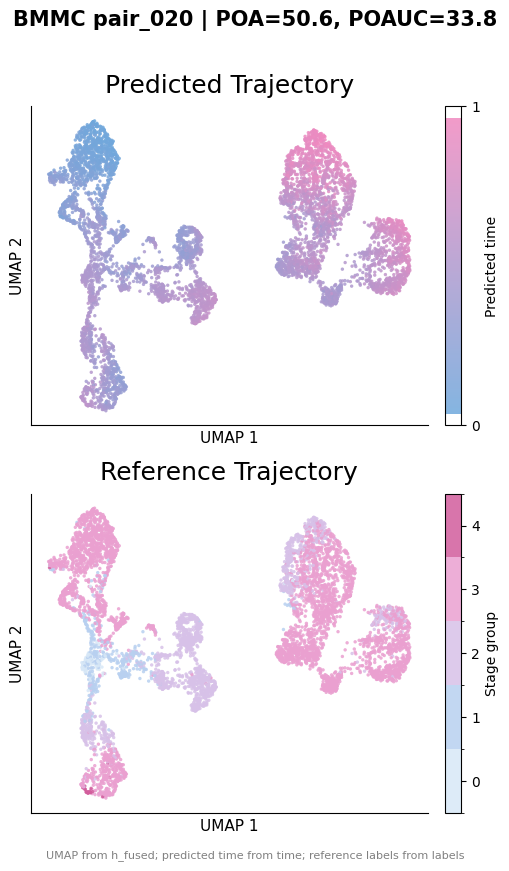

{'run_dir': '/data5/zhangye/ATLAS/results/table2/BMMC/pair_020',
 'embedding_key': 'h_fused',
 'time_key': 'time',
 'label_key': 'labels',
 'n_cells': 6191,
 'n_valid_stage_labels': 6191}

In [6]:

# Test on one ratio first
info = plot_simple_t3_panel(ROOT / 'pair_020', save=True, show=True)
info


In [7]:

# Batch-generate all ratios
summary = []
for d in PAIR_DIRS:
    run_dir = ROOT / d
    info = plot_simple_t3_panel(run_dir, save=True, show=False)
    summary.append(info)

summary_df = pd.DataFrame(summary)
summary_df


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple/pair_000_trajectory_simple.png
Saved: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple/pair_000_trajectory_simple.pdf


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple/pair_020_trajectory_simple.png
Saved: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple/pair_020_trajectory_simple.pdf


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


...

/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple/pair_080_trajectory_simple.png
Saved: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple/pair_080_trajectory_simple.pdf


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple/pair_100_trajectory_simple.png
Saved: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple/pair_100_trajectory_simple.pdf


,run_dir,embedding_key,time_key,label_key,n_cells,n_valid_stage_labels
0,/data5/zhangye/ATLAS/results/table2/BMMC/pair_000,h_fused,time,labels,5161,5161
1,/data5/zhangye/ATLAS/results/table2/BMMC/pair_020,h_fused,time,labels,6191,6191
2,/data5/zhangye/ATLAS/results/table2/BMMC/pair_040,h_fused,time,labels,7174,7174
3,/data5/zhangye/ATLAS/results/table2/BMMC/pair_060,h_fused,time,labels,8211,8211
4,/data5/zhangye/ATLAS/results/table2/BMMC/pair_080,h_fused,time,labels,9319,9319
5,/data5/zhangye/ATLAS/results/table2/BMMC/pair_100,h_fused,time,labels,10315,10315


In [8]:

summary_df.to_csv(OUT_DIR / 'trajectory_visualization_summary.csv', index=False)
print('Saved:', OUT_DIR / 'trajectory_visualization_summary.csv')
print('All figures saved to:', OUT_DIR)


Saved: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple/trajectory_visualization_summary.csv
All figures saved to: /data5/zhangye/ATLAS/results/table2/BMMC/trajectory_visualizations_simple



## Notes

1. **Top panel** uses the predicted time from `predictions.npz` and colors it continuously from 0 to 1.
2. **Bottom panel** uses the same UMAP coordinates but colors the cells by the 5 stage groups derived from your `stage_map`.
3. If `predictions.npz` does not contain labels, the notebook falls back to `T3_stage_reference.csv`.
4. If `umap-learn` is not installed, it automatically falls back to PCA(2), but UMAP is preferred.
